# Bài thực hành chương 2 — Các thuật toán xử lý ảnh

## Phần I: Toán tử điểm ảnh

Mục tiêu:
- Thực hiện thay đổi độ sáng và độ tương phản.
- Tạo ảnh âm bản.
- Phân ngưỡng ảnh xám.
- Khảo sát ảnh hưởng của tham số trên cùng ảnh đầu vào.

Các phép biến đổi được áp dụng độc lập lên ảnh gốc.

### 1. Xác định đường dẫn và import

In [3]:
from pathlib import Path
import sys

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Hỗ trợ notebook chạy từ thư mục project hoặc notebooks.
current = Path.cwd().resolve()
ROOT = next(
    (
        folder
        for folder in [current, *current.parents]
        if (folder / "src" / "point_ops.py").is_file()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "Không tìm thấy project có src/point_ops.py"
    )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.image_io import read_image, save_image
from src.point_ops import (
    brightness,
    contrast,
    negative,
    binary_threshold,
)

print("Project:", ROOT)

Project: C:\Users\NAO\Downloads\image-processing-lab2


### 2. Đọc ảnh

Ảnh màu: (1440, 2560, 3)
Ảnh xám: (1440, 2560)
Kiểu dữ liệu: uint8
Min/max: 0 255


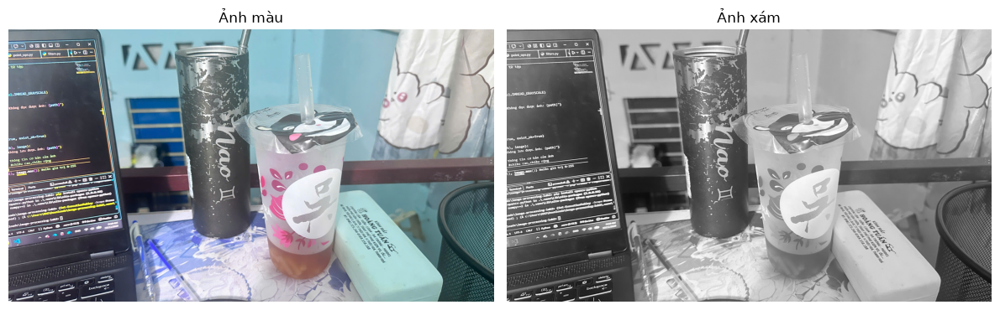

In [4]:
image_path = ROOT / "data" / "original" / "desk.jpg"

bgr = read_image(image_path)
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)

print("Ảnh màu:", bgr.shape)
print("Ảnh xám:", gray.shape)
print("Kiểu dữ liệu:", gray.dtype)
print("Min/max:", gray.min(), gray.max())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(rgb)
axes[0].set_title("Ảnh màu")

axes[1].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Ảnh xám")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

### 3.Tạo hàm hiển thị để dùng lại

In [5]:
def show_comparison(images, titles, save_path=None):
    fig, axes = plt.subplots(
        1, len(images),
        figsize=(5 * len(images), 5),
        squeeze=False,
    )

    for ax, image, title in zip(axes[0], images, titles):
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()

    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=180, bbox_inches="tight")

    plt.show()
    plt.close(fig)

các bước theo yêu cầu phần 1

1. Thay đổi độ sáng: Tăng hoặc giảm độ sáng của toàn bộ hình ảnh bằng cách cộng hoặc trừ một giá trị cố định cho mỗi điểm ảnh

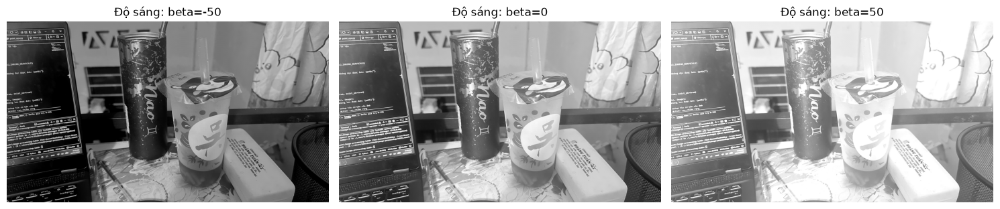

In [6]:
# Thay đổi độ sáng
betas = [-50, 0, 50]
brightness_results = [
    brightness(gray, beta)
    for beta in betas
]

show_comparison(
    brightness_results,
    [f"Độ sáng: beta={beta}" for beta in betas],
    ROOT / "outputs" / "figures" / "brightness.png",
)

**Nhận xét:** Với β = −50, ảnh tối đi rõ, màn hình laptop và giỏ gần như đen nên khó phân biệt chi tiết. Với β = +50, ảnh sáng hơn và vùng tối dễ nhìn hơn, nhưng rèm, tường và hộp tiến sát mức 255, họa tiết trên rèm nhạt đi. β = 0 giữ nguyên ảnh.

Nguyên nhân: phép cộng dịch mọi pixel cùng một lượng, nên các giá trị vượt 0–255 bị clipping. Nhiều mức cường độ khác nhau bị gộp về cùng đen hoặc trắng, và chi tiết đã mất không phục hồi được.

2. Thay đổi tương phản: Tăng hoặc giảm độ tương phản bằng cách nhân mỗi điểm ảnh với một hằng số.

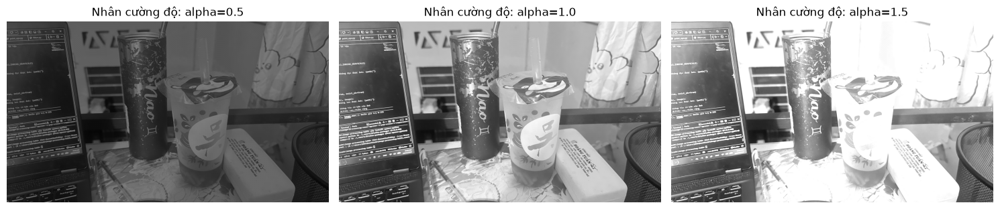

In [7]:
# thay đổi tương phản
alphas = [0.5, 1.0, 1.5]
contrast_results = [
    contrast(gray, alpha)
    for alpha in alphas
]

show_comparison(
    contrast_results,
    [f"Nhân cường độ: alpha={alpha}" for alpha in alphas],
    ROOT / "outputs" / "figures" / "contrast.png",
)

**Nhận xét:** Với α = 0.5, ảnh tối và phẳng hơn, chênh lệch giữa các vùng giảm. Với α = 1.5, rèm, tường, cốc và hộp cháy gần trắng hoàn toàn, còn vùng tối (laptop, giỏ) thay đổi ít vì nhân với số nhỏ.

Nguyên nhân: trước clipping, chênh lệch hai pixel đổi theo hệ số α. Nhưng phép nhân cũng đổi luôn mức sáng, nên không thể coi đây là thay đổi “thuần” độ tương phản. Các pixel 180 và 250 đều thành 255 khi α = 1.5 nên mất khác biệt giữa chúng.

3. Biến đổi âm bản: Đảo ngược các giá trị điểm ảnh, tạo ra ảnh âm bản.

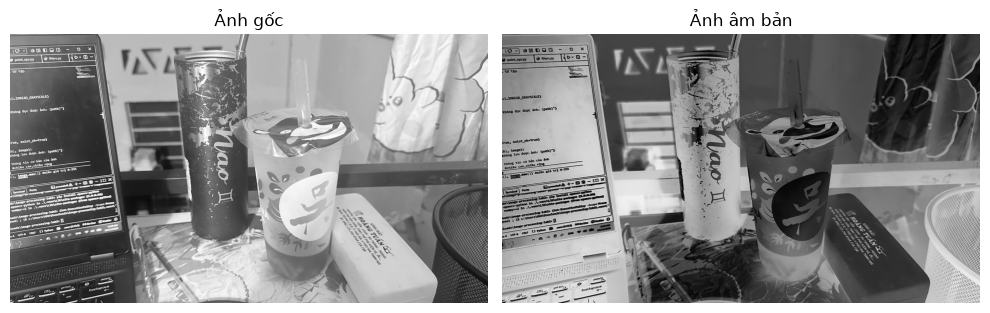

In [8]:
negative_result = negative(gray)

show_comparison(
    [gray, negative_result],
    ["Ảnh gốc", "Ảnh âm bản"],
    ROOT / "outputs" / "figures" / "negative.png",
)

**Nhận xét:** Vùng tối (màn hình laptop, giỏ) trở nên sáng, vùng sáng (rèm, hộp, cốc) trở nên tối. Vị trí và hình dạng vật thể không đổi.
Phép g = 255 − f chỉ đảo thứ tự sáng–tối, không tạo thêm chi tiết. Với uint8, kết quả luôn nằm trong 0–255 nên không cần clipping.

4. Phân ngưỡng: Tạo ảnh nhị phân bằng cách so sánh giá trị mỗi điểm ảnh với một ngưỡng nhất định.

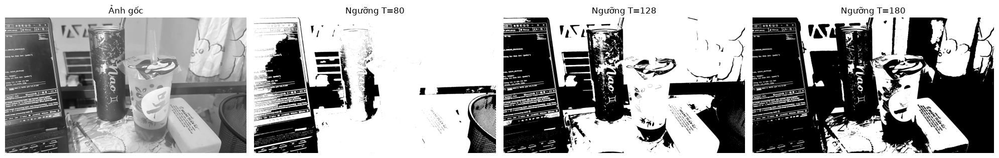

In [9]:
thresholds = [80, 128, 180]
threshold_results = [
    binary_threshold(gray, value)
    for value in thresholds
]

show_comparison(
    [gray, *threshold_results],
    ["Ảnh gốc", *[f"Ngưỡng T={t}" for t in thresholds]],
    ROOT / "outputs" / "figures" / "threshold.png",
)

**Nhận xét:**Khi T tăng từ 80 lên 128 rồi 180, vùng trắng thu hẹp và vùng đen mở rộng, vì ít pixel đạt điều kiện f ≥ T. Với T = 80 phần lớn ảnh thành trắng; với T = 180 chỉ còn vùng rất sáng (rèm, hộp, mặt cốc). Không ngưỡng nào tách trọn vẹn từng vật: thân bình có cả vùng sáng lẫn tối, còn cốc, hộp và tường có mức xám gần nhau. Các vùng bị bóng (cạnh laptop, giỏ) bị xếp vào nhóm đen dù thuộc vật khác nhau.

Kết luận: phân ngưỡng toàn cục chỉ dựa vào cường độ, chưa hiểu đối tượng và kém khi ánh sáng không đều.

Lưu ảnh và kiểm tra chức năng

In [10]:
# lưu ảnh riêng
output_dir = ROOT / "outputs" / "images" / "point_ops"

for beta, result in zip(betas, brightness_results):
    save_image(output_dir / f"desk_brightness_{beta}.png", result)

for alpha, result in zip(alphas, contrast_results):
    save_image(output_dir / f"desk_contrast_{alpha}.png", result)

save_image(output_dir / "desk_negative.png", negative_result)

for value, result in zip(thresholds, threshold_results):
    save_image(output_dir / f"desk_threshold_{value}.png", result)

In [11]:
# Kiểm tra các hàm
assert np.array_equal(brightness(gray, 0), gray)
assert np.array_equal(contrast(gray, 1), gray)
assert np.array_equal(negative(negative(gray)), gray)

assert set(np.unique(binary_threshold(gray, 128))) <= {0, 255}

sample = np.array([[0, 250, 255]], dtype=np.uint8)
assert np.array_equal(
    brightness(sample, 30),
    np.array([[30, 255, 255]], dtype=np.uint8),
)

sample = np.array([[0, 100, 200]], dtype=np.uint8)
assert np.array_equal(
    contrast(sample, 0.5),
    np.array([[0, 50, 100]], dtype=np.uint8),
)

print("Các kiểm tra phần I đều đạt.")


Các kiểm tra phần I đều đạt.


## Phần II: Lọc tuyến tính

Mục tiêu:
- Thực hiện lọc trung bình, lọc Gaussian và làm sắc nét.
- Khảo sát ảnh hưởng của kích thước kernel và sigma.
- Quan sát sự thay đổi tại đường biên và các chi tiết nhỏ.

Mỗi phương pháp được áp dụng độc lập lên cùng ảnh xám đầu vào.

In [12]:
from src.filters import (
    mean_filter,
    gaussian_filter,
    sharpen,
)

### 1. Lọc trung bình

Mỗi pixel đầu ra được tính bằng trung bình các pixel
trong vùng lân cận k × k.

Thực nghiệm thay đổi k = 3, 5, 9 để quan sát mức làm mờ.

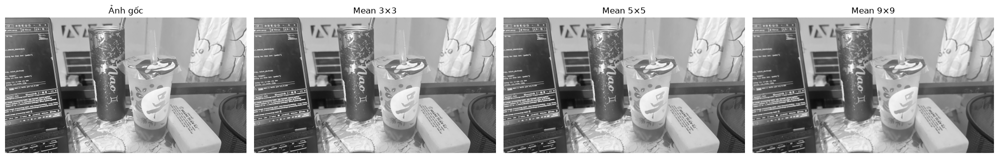

In [13]:
mean_sizes = [3, 5, 9]

mean_results = [
    mean_filter(gray, k=k)
    for k in mean_sizes
]

show_comparison(
    [gray, *mean_results],
    ["Ảnh gốc", *[f"Mean {k}×{k}" for k in mean_sizes]],
    ROOT / "outputs" / "figures" / "mean_comparison.png",
)

Nhận xét: Khi k tăng từ 3 lên 9, họa tiết thân bình, nét chữ “Nao” và chữ trên màn hình mờ dần. k = 3 gần ảnh gốc, k = 9 mất nhiều chi tiết nhỏ.
Nguyên nhân: cửa sổ lớn hơn trộn pixel ở hai phía đường biên nhiều hơn, vì mọi pixel trong cửa sổ có trọng số bằng nhau.

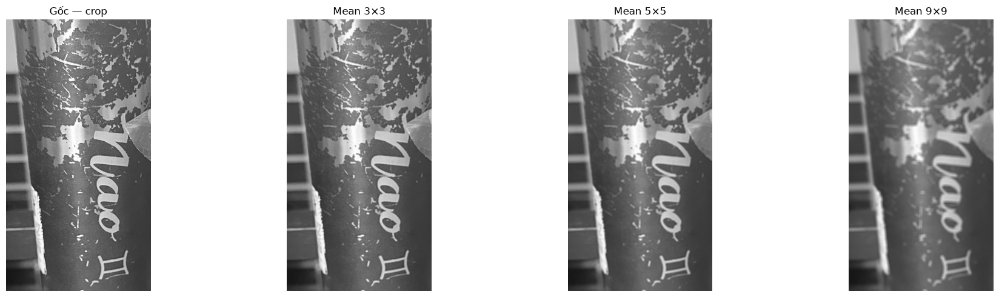

In [14]:
# Vùng thân bình; tọa độ xác định theo tỷ lệ ảnh.
h, w = gray.shape
x1, x2 = int(0.34 * w), int(0.49 * w)
y1, y2 = int(0.15 * h), int(0.65 * h)

def crop_detail(image):
    return image[y1:y2, x1:x2]

show_comparison(
    [crop_detail(image) for image in [gray, *mean_results]],
    ["Gốc — crop", *[f"Mean {k}×{k}" for k in mean_sizes]],
    ROOT / "outputs" / "figures" / "mean_crop.png",
)

## 2. Lọc Gaussian: 
Làm mờ ảnh một cách tự nhiên hơn bằng cách sử dụng kernel Gaussian

Gaussian tính trung bình có trọng số:
pixel gần tâm kernel có trọng số lớn hơn.

Giữ kernel 9 × 9, thay sigma = 0.8, 1.5, 2.5.

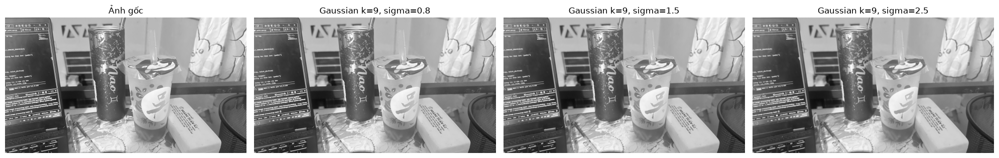

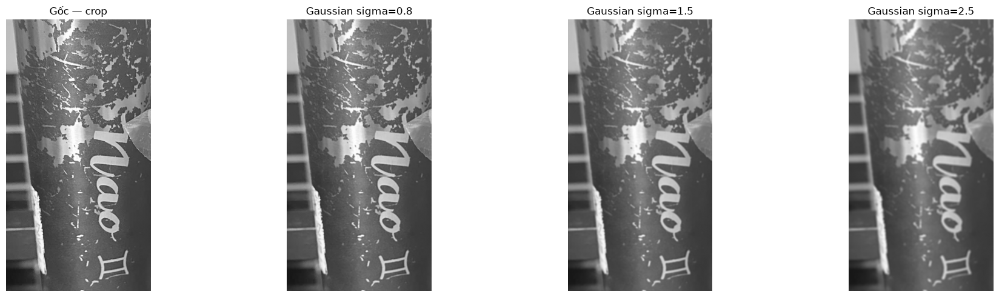

In [15]:
gaussian_k = 9
sigmas = [0.8, 1.5, 2.5]

gaussian_results = [
    gaussian_filter(gray, k=gaussian_k, sigma=sigma)
    for sigma in sigmas
]

show_comparison(
    [gray, *gaussian_results],
    [
        "Ảnh gốc",
        *[f"Gaussian k=9, sigma={s}" for s in sigmas],
    ],
    ROOT / "outputs" / "figures" / "gaussian_comparison.png",
)

show_comparison(
    [crop_detail(image) for image in [gray, *gaussian_results]],
    [
        "Gốc — crop",
        *[f"Gaussian sigma={s}" for s in sigmas],
    ],
    ROOT / "outputs" / "figures" / "gaussian_crop.png",
)

Nhận xét: Khi sigma tăng, ảnh mịn và mờ hơn. Ở sigma = 0.8 họa tiết thân bình còn khá rõ; ở sigma = 2.5 họa tiết và nét chữ mềm đi nhiều.
Nguyên nhân: sigma quyết định độ trải của trọng số, sigma lớn thì các pixel xa tâm đóng góp nhiều hơn. Gaussian vẫn làm mờ đường biên, nên mượt không có nghĩa là giữ được cạnh.

### 3. Làm sắc nét

Kernel sử dụng: ở file filters.py
Pixel trung tâm được tăng trọng số, đồng thời trừ đóng góp
của bốn pixel lân cận để làm nổi bật sự khác biệt cục bộ.

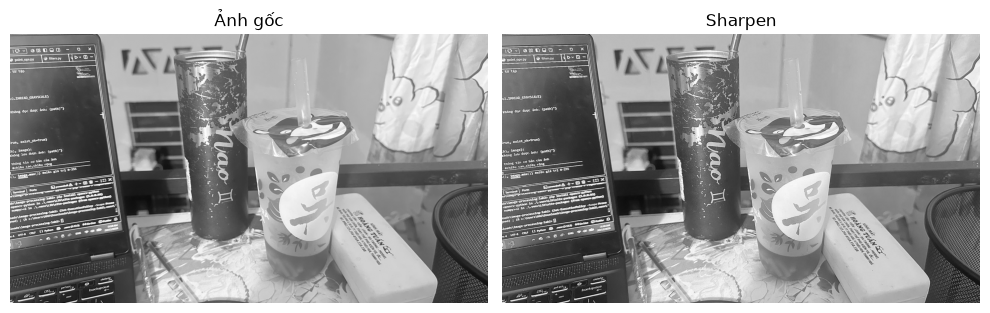

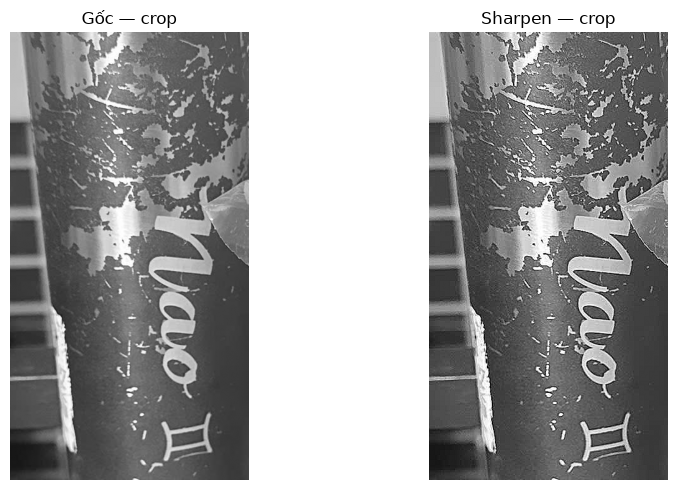

In [16]:
sharpen_result = sharpen(gray)

show_comparison(
    [gray, sharpen_result],
    ["Ảnh gốc", "Sharpen"],
    ROOT / "outputs" / "figures" / "sharpen_comparison.png",
)

show_comparison(
    [crop_detail(gray), crop_detail(sharpen_result)],
    ["Gốc — crop", "Sharpen — crop"],
    ROOT / "outputs" / "figures" / "sharpen_crop.png",
)

Nhận xét: Viền chữ, viền thân bình và họa tiết nổi rõ hơn ảnh gốc, nhưng bề mặt cũng gắt và hạt hơn.

Nguyên nhân: kernel có tổng hệ số bằng 1 nên vùng đồng nhất giữ nguyên, còn tại nơi cường độ đổi nhanh, nó khuếch đại chênh lệch cục bộ, nên cả chi tiết lẫn nhiễu đều rõ hơn.

4. Lưu kết quả

In [17]:
filter_output_dir = ROOT / "outputs" / "images" / "linear_filters"

for k, result in zip(mean_sizes, mean_results):
    save_image(
        filter_output_dir / f"desk_mean_k{k}.png",
        result,
    )

for sigma, result in zip(sigmas, gaussian_results):
    save_image(
        filter_output_dir / f"desk_gaussian_k9_sigma{sigma}.png",
        result,
    )

save_image(
    filter_output_dir / "desk_sharpen.png",
    sharpen_result,
)

## Phần III: Bài tập nâng cao

### 1. Phát hiện cạnh bằng Sobel và Prewitt

Mục tiêu:
- Tính gradient theo hai hướng x và y.
- Kết hợp hai hướng để tạo bản đồ độ lớn gradient.
- Quan sát đường biên vật thể và các chi tiết trong ảnh.

Đầu vào: cùng ảnh xám, chưa làm mịn.
Đầu ra: Gx, Gy và độ lớn gradient.

In [18]:
from src.edges import gradients, gradient_to_uint8
from src.filters import apply_kernel

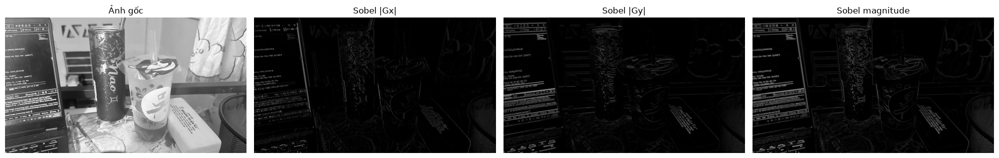

In [19]:
# chạy sobel
sobel_gx, sobel_gy, sobel_mag = gradients(
    gray, method="sobel"
)

sobel_x_display = gradient_to_uint8(sobel_gx)
sobel_y_display = gradient_to_uint8(sobel_gy)
sobel_mag_display = gradient_to_uint8(sobel_mag)

show_comparison(
    [
        gray,
        sobel_x_display,
        sobel_y_display,
        sobel_mag_display,
    ],
    [
        "Ảnh gốc",
        "Sobel |Gx|",
        "Sobel |Gy|",
        "Sobel magnitude",
    ],
    ROOT / "outputs" / "figures" / "sobel.png",
)

**Nhận xét:** Bản đồ gradient sáng ở viền laptop, dòng chữ trên màn hình, viền thân bình, chữ “Nao” và viền cốc. |Gx| nổi các nét gần dọc (cạnh thân bình), |Gy| nổi các nét gần ngang (các dòng chữ trên màn hình). Độ lớn gradient gộp cả hai hướng. Hình trông tối vì chuẩn hóa theo giá trị lớn nhất, trong khi phần lớn pixel có thay đổi cường độ nhỏ.

Gradient phản ứng với mọi thay đổi cường độ, nên chữ và họa tiết cũng xuất hiện như cạnh. Bản đồ này chưa cho biết vật thể là gì.

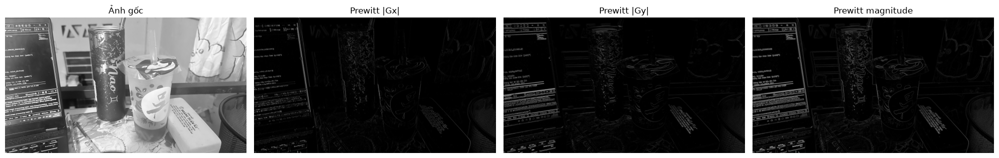

In [20]:
# Chạy Prewitt
prewitt_gx, prewitt_gy, prewitt_mag = gradients(
    gray, method="prewitt"
)

prewitt_x_display = gradient_to_uint8(prewitt_gx)
prewitt_y_display = gradient_to_uint8(prewitt_gy)
prewitt_mag_display = gradient_to_uint8(prewitt_mag)

show_comparison(
    [
        gray,
        prewitt_x_display,
        prewitt_y_display,
        prewitt_mag_display,
    ],
    [
        "Ảnh gốc",
        "Prewitt |Gx|",
        "Prewitt |Gy|",
        "Prewitt magnitude",
    ],
    ROOT / "outputs" / "figures" / "prewitt.png",
)

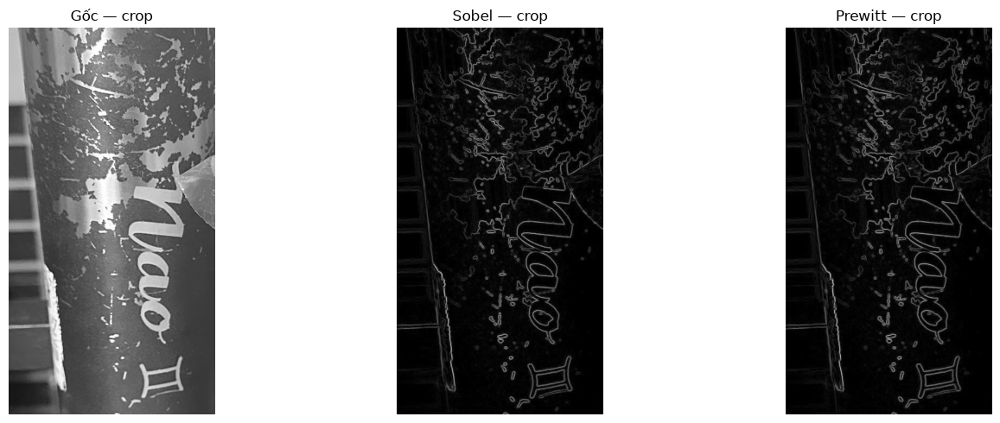

In [21]:
# So sánh Sobel và Prewitt
show_comparison(
    [
        crop_detail(gray),
        crop_detail(sobel_mag_display),
        crop_detail(prewitt_mag_display),
    ],
    [
        "Gốc — crop",
        "Sobel — crop",
        "Prewitt — crop",
    ],
    ROOT / "outputs" / "figures" / "sobel_prewitt_crop.png",
)

**Nhận xét:**Trên cùng vùng thân bình, hai phương pháp cho các đường cạnh ở vị trí gần giống nhau: viền chữ “Nao”, viền đốm họa tiết, ký hiệu phía dưới. Khác biệt chủ yếu là trọng số: Sobel dùng 1–2–1, Prewitt dùng 1–1–1 theo hướng làm mịn.

Mỗi bản đồ được chuẩn hóa riêng, nên không dựa vào độ sáng hình để kết luận phương pháp nào có đáp ứng mạnh hơn. Chưa có nhãn cạnh chuẩn, nên không kết luận phương pháp nào chính xác hơn.

Kiểm tra gradient bằng ảnh đơn giản

In [22]:
# Ảnh đồng nhất không có thay đổi cường độ.
constant = np.full((20, 20), 100, dtype=np.uint8)

for method in ["sobel", "prewitt"]:
    gx, gy, mag = gradients(constant, method)

    assert np.allclose(gx, 0)
    assert np.allclose(gy, 0)
    assert np.allclose(mag, 0)

# Một ranh giới dọc: nửa trái đen, nửa phải trắng.
vertical_step = np.zeros((20, 20), dtype=np.uint8)
vertical_step[:, 10:] = 255

for method in ["sobel", "prewitt"]:
    gx, gy, mag = gradients(vertical_step, method)

    assert np.max(np.abs(gx)) > 0
    assert np.allclose(gy, 0)

print("Các kiểm tra Sobel và Prewitt đều đạt.")

Các kiểm tra Sobel và Prewitt đều đạt.


### 2. Kernel tùy chỉnh

Thiết kế hai hiệu ứng:
1. Làm mịn theo chiều ngang bằng trung bình ba pixel.
2. Làm mịn theo chiều dọc bằng trung bình ba pixel.

Hai kernel đều có tổng hệ số bằng 1 để bảo toàn
cường độ ở vùng đồng nhất.

Kernel làm mịn ngang:
 [[0.         0.         0.        ]
 [0.33333334 0.33333334 0.33333334]
 [0.         0.         0.        ]]
Kernel làm mịn dọc:
 [[0.         0.33333334 0.        ]
 [0.         0.33333334 0.        ]
 [0.         0.33333334 0.        ]]


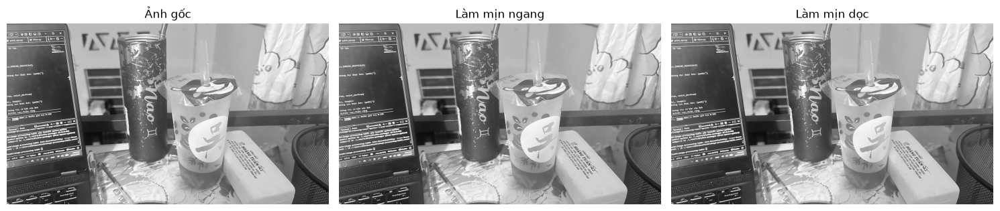

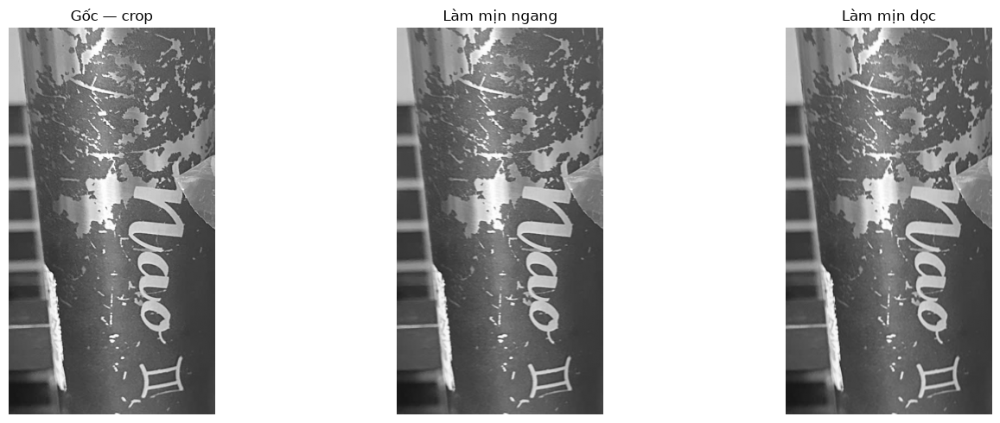

In [23]:
horizontal_kernel = np.array([
    [0, 0, 0],
    [1, 1, 1],
    [0, 0, 0],
], dtype=np.float32) / 3

vertical_kernel = np.array([
    [0, 1, 0],
    [0, 1, 0],
    [0, 1, 0],
], dtype=np.float32) / 3


def kernel_result_to_uint8(result):
    return np.clip(result, 0, 255).astype(np.uint8)


horizontal_result = kernel_result_to_uint8(
    apply_kernel(gray, horizontal_kernel)
)

vertical_result = kernel_result_to_uint8(
    apply_kernel(gray, vertical_kernel)
)

print("Kernel làm mịn ngang:\n", horizontal_kernel)
print("Kernel làm mịn dọc:\n", vertical_kernel)

show_comparison(
    [gray, horizontal_result, vertical_result],
    ["Ảnh gốc", "Làm mịn ngang", "Làm mịn dọc"],
    ROOT / "outputs" / "figures" / "custom_kernels.png",
)

show_comparison(
    [
        crop_detail(gray),
        crop_detail(horizontal_result),
        crop_detail(vertical_result),
    ],
    ["Gốc — crop", "Làm mịn ngang", "Làm mịn dọc"],
    ROOT / "outputs" / "figures" / "custom_kernels_crop.png",
)

**Nhận xét:** Trên hình chữ thập, kernel làm mịn ngang khiến nét dọc
trải sang trái và phải; kernel làm mịn dọc khiến nét ngang trải
lên trên và dưới. Kết quả minh họa hướng tác động của từng kernel.

Trên ảnh thực tế, hiệu ứng tương đối nhẹ vì mỗi kernel chỉ lấy
trung bình ba pixel. Tổng hệ số bằng 1 giúp bảo toàn cường độ
của vùng đồng nhất trong tính toán số thực; khi chuyển về uint8
có thể có sai khác nhỏ do lượng tử hóa.

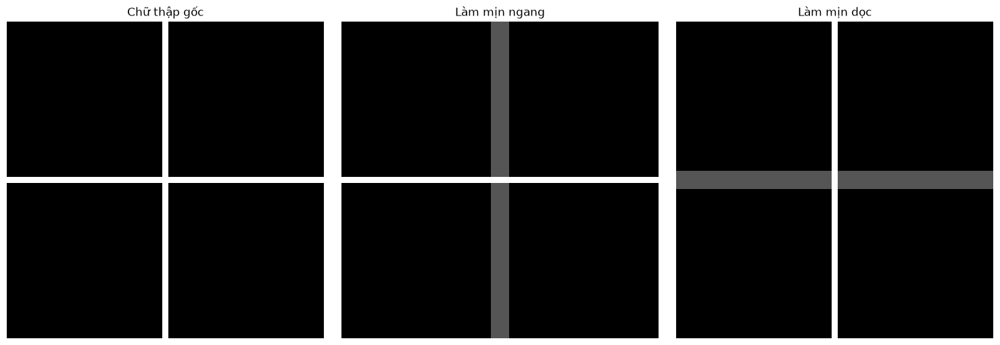

In [24]:
# Kiểm chứng kernel bằng hình chữ thập
pattern = np.zeros((51, 51), dtype=np.uint8)
pattern[25, :] = 255
pattern[:, 25] = 255

pattern_horizontal = kernel_result_to_uint8(
    apply_kernel(pattern, horizontal_kernel)
)

pattern_vertical = kernel_result_to_uint8(
    apply_kernel(pattern, vertical_kernel)
)

show_comparison(
    [pattern, pattern_horizontal, pattern_vertical],
    ["Chữ thập gốc", "Làm mịn ngang", "Làm mịn dọc"],
    ROOT / "outputs" / "figures" / "custom_kernel_pattern.png",
)

- Kernel ngang làm nét dọc trải sang trái/phải.
- Kernel dọc làm nét ngang trải lên trên/dưới.
Hình này là dữ liệu kiểm chứng bổ sung, giúp giải thích kernel; ảnh desk.jpg vẫn là đầu vào thực nghiệm chính.

In [25]:
# lưu kết quả
edge_dir = ROOT / "outputs" / "images" / "edges"

save_image(edge_dir / "desk_sobel_x.png", sobel_x_display)
save_image(edge_dir / "desk_sobel_y.png", sobel_y_display)
save_image(edge_dir / "desk_sobel_magnitude.png", sobel_mag_display)

save_image(edge_dir / "desk_prewitt_x.png", prewitt_x_display)
save_image(edge_dir / "desk_prewitt_y.png", prewitt_y_display)
save_image(
    edge_dir / "desk_prewitt_magnitude.png",
    prewitt_mag_display,
)

# Giữ dữ liệu gradient gốc để sử dụng lại khi cần.
np.savez_compressed(
    edge_dir / "desk_gradients.npz",
    sobel_gx=sobel_gx,
    sobel_gy=sobel_gy,
    sobel_magnitude=sobel_mag,
    prewitt_gx=prewitt_gx,
    prewitt_gy=prewitt_gy,
    prewitt_magnitude=prewitt_mag,
)

custom_dir = ROOT / "outputs" / "images" / "custom_kernels"

save_image(custom_dir / "desk_horizontal.png", horizontal_result)
save_image(custom_dir / "desk_vertical.png", vertical_result)

### 3. Lọc phi tuyến và so sánh các bộ lọc

Mục tiêu:
- Áp dụng median và bilateral.
- So sánh mean, Gaussian, median và bilateral trên cùng ảnh nhiễu.
- Đánh giá mức giảm nhiễu và mức bảo toàn chi tiết.

Ảnh trước khi thêm nhiễu được dùng làm tham chiếu.
Đây là đánh giá với nhiễu nhân tạo, không phải nhãn sạch tuyệt đối.

In [26]:
import pandas as pd
from time import perf_counter

from src.filters import (
    mean_filter,
    gaussian_filter,
    median_filter,
    bilateral_filter,
)
from src.noise import gaussian_noise, salt_pepper_noise
from src.evaluation import evaluate

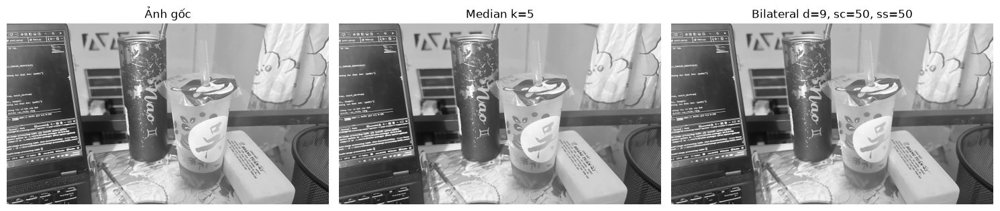

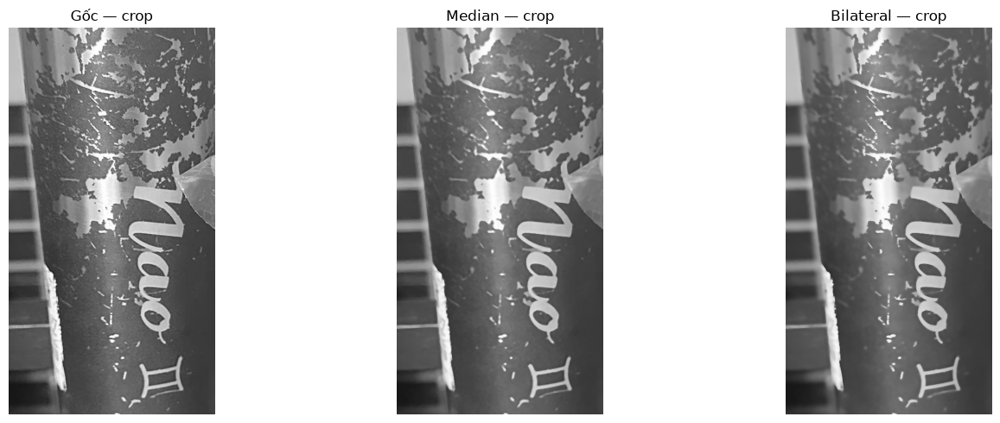

In [27]:
# Quan sát median và bilateral trên ảnh gốc
median_original = median_filter(gray, k=5)

bilateral_original = bilateral_filter(
    gray,
    d=9,
    sigma_color=50,
    sigma_space=50,
)

show_comparison(
    [gray, median_original, bilateral_original],
    ["Ảnh gốc", "Median k=5", "Bilateral d=9, sc=50, ss=50"],
    ROOT / "outputs" / "figures" / "nonlinear_original.png",
)

show_comparison(
    [
        crop_detail(gray),
        crop_detail(median_original),
        crop_detail(bilateral_original),
    ],
    ["Gốc — crop", "Median — crop", "Bilateral — crop"],
    ROOT / "outputs" / "figures" / "nonlinear_original_crop.png",
)

Nhận xét: Trên vùng crop, median k = 5 loại bớt các đốm sáng rất nhỏ nhưng nét chữ vẫn rõ; các nét mảnh có thể hơi tròn lại. Bilateral làm mịn bề mặt thân bình mà viền chữ và viền bình vẫn khá nét. Trên ảnh lớn 2560×1440, khác biệt giữa hai bộ lọc và ảnh gốc khá nhẹ.

Median chọn trung vị nên bỏ qua giá trị cực đoan; bilateral giảm trọng số của pixel có cường độ khác nhiều, nên hạn chế trộn qua cạnh.

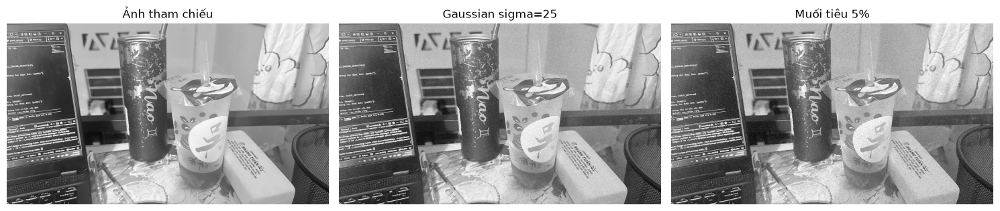

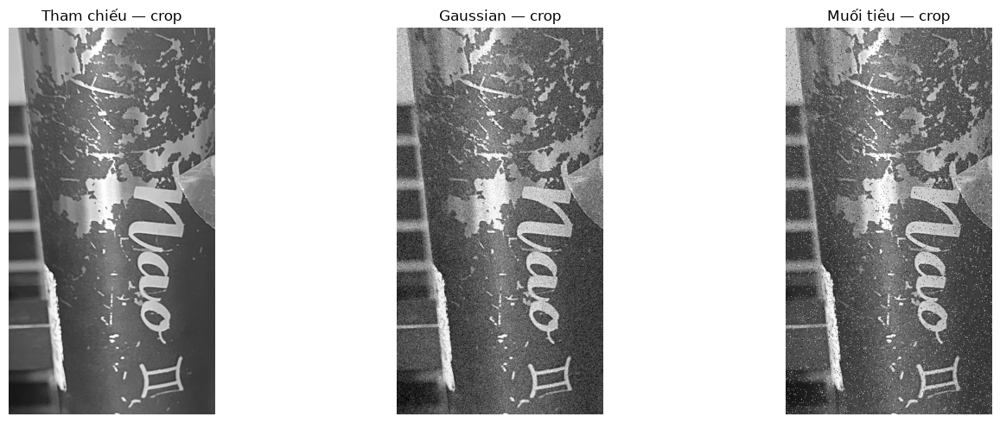

In [28]:
# Tạo hai ảnh nhiễu dùng chung
SEED = 42

noisy_images = {
    "gaussian_sigma25": gaussian_noise(
        gray, sigma=25, seed=SEED
    ),
    "salt_pepper_05": salt_pepper_noise(
        gray, amount=0.05, seed=SEED
    ),
}

show_comparison(
    [gray, *noisy_images.values()],
    ["Ảnh tham chiếu", "Gaussian sigma=25", "Muối tiêu 5%"],
    ROOT / "outputs" / "figures" / "noise_examples.png",
)

show_comparison(
    [crop_detail(image) for image in [gray, *noisy_images.values()]],
    ["Tham chiếu — crop", "Gaussian — crop", "Muối tiêu — crop"],
    ROOT / "outputs" / "figures" / "noise_examples_crop.png",
)

Mỗi ảnh nhiễu được tạo một lần, rồi đưa nguyên ảnh đó vào mọi bộ lọc.

In [29]:
# định nghĩa các bộ lọc để thử nghiệm
filter_methods = {
    "Mean": {
        "params": "k=5",
        "run": lambda image: mean_filter(image, k=5),
    },
    "Gaussian": {
        "params": "k=5, sigma=1.0",
        "run": lambda image: gaussian_filter(
            image, k=5, sigma=1.0
        ),
    },
    "Median": {
        "params": "k=5",
        "run": lambda image: median_filter(image, k=5),
    },
    "Bilateral": {
        "params": "d=9, sigma_color=50, sigma_space=50",
        "run": lambda image: bilateral_filter(
            image, d=9, sigma_color=50, sigma_space=50
        ),
    },
}

In [30]:
# Chạy thí nghiệm, tính chỉ số và lưu ảnh
denoise_dir = ROOT / "outputs" / "images" / "denoising"
metrics_dir = ROOT / "outputs" / "metrics"
metrics_dir.mkdir(parents=True, exist_ok=True)

results_by_noise = {}
rows = []

for noise_name, noisy in noisy_images.items():
    results = {}

    save_image(
        denoise_dir / f"desk_{noise_name}_noisy.png",
        noisy,
    )

    # Baseline: chất lượng ảnh nhiễu trước khi lọc.
    rows.append({
        "image": "desk",
        "noise": noise_name,
        "method": "Noisy baseline",
        "params": "-",
        **evaluate(gray, noisy),
        "time_ms": np.nan,
    })

    for method_name, specification in filter_methods.items():
        function = specification["run"]

        # Khởi động trước khi đo.
        function(noisy)

        elapsed = []
        for _ in range(3):
            start = perf_counter()
            filtered = function(noisy)
            elapsed.append((perf_counter() - start) * 1000)

        results[method_name] = filtered

        rows.append({
            "image": "desk",
            "noise": noise_name,
            "method": method_name,
            "params": specification["params"],
            **evaluate(gray, filtered),
            "time_ms": float(np.median(elapsed)),
        })

        save_image(
            denoise_dir / f"desk_{noise_name}_{method_name.lower()}.png",
            filtered,
        )

    results_by_noise[noise_name] = results

metrics_df = pd.DataFrame(rows)

metrics_df.to_csv(
    metrics_dir / "desk_denoising.csv",
    index=False,
    encoding="utf-8-sig",
)

display(metrics_df.round(3))

,image,noise,method,params,MSE,PSNR,SSIM,time_ms
0,desk,gaussian_sigma25,Noisy baseline,-,592.843,20.401,0.257,NaN
1,desk,gaussian_sigma25,Mean,k=5,190.399,25.334,0.761,6.981
2,desk,gaussian_sigma25,Gaussian,"k=5, sigma=1.0",116.010,27.486,0.688,1.326
3,desk,gaussian_sigma25,Median,k=5,141.384,26.627,0.713,7.910
4,desk,gaussian_sigma25,Bilateral,"d=9, sigma_color=50, sigma_space=50",87.648,28.703,0.711,14.705
5,desk,salt_pepper_05,Noisy baseline,-,1014.948,18.066,0.314,NaN
6,desk,salt_pepper_05,Mean,k=5,218.425,24.738,0.702,3.981
7,desk,salt_pepper_05,Gaussian,"k=5, sigma=1.0",161.313,26.054,0.627,1.277
8,desk,salt_pepper_05,Median,k=5,91.660,28.509,0.936,3.624
9,desk,salt_pepper_05,Bilateral,"d=9, sigma_color=50, sigma_space=50",805.997,19.067,0.394,18.857


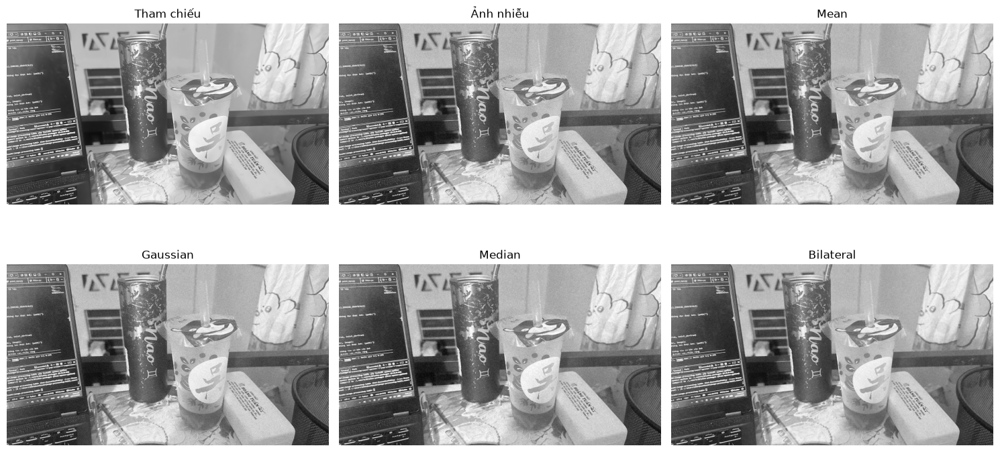

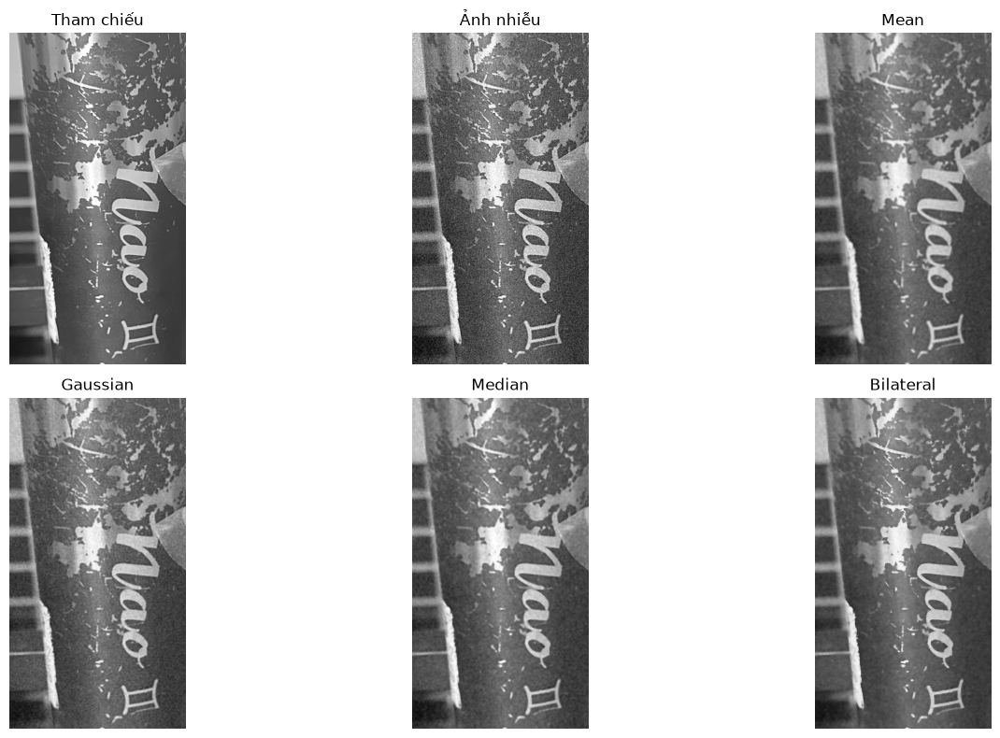

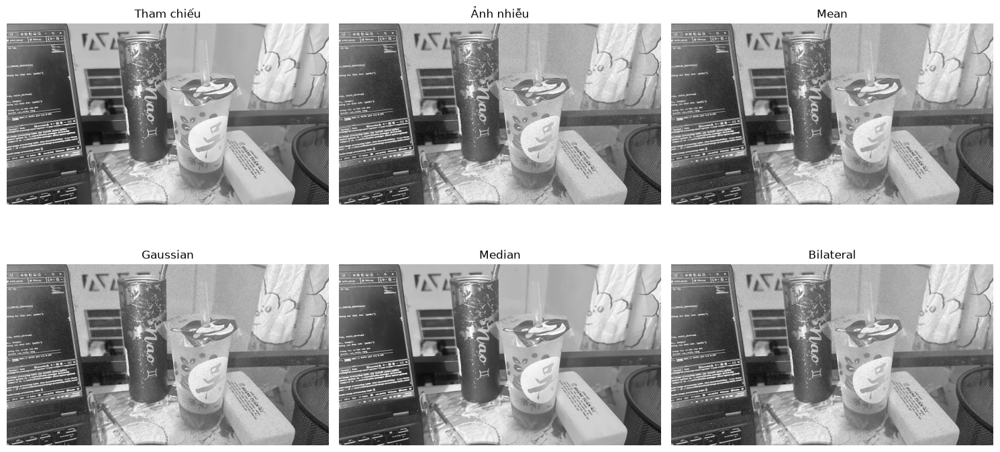

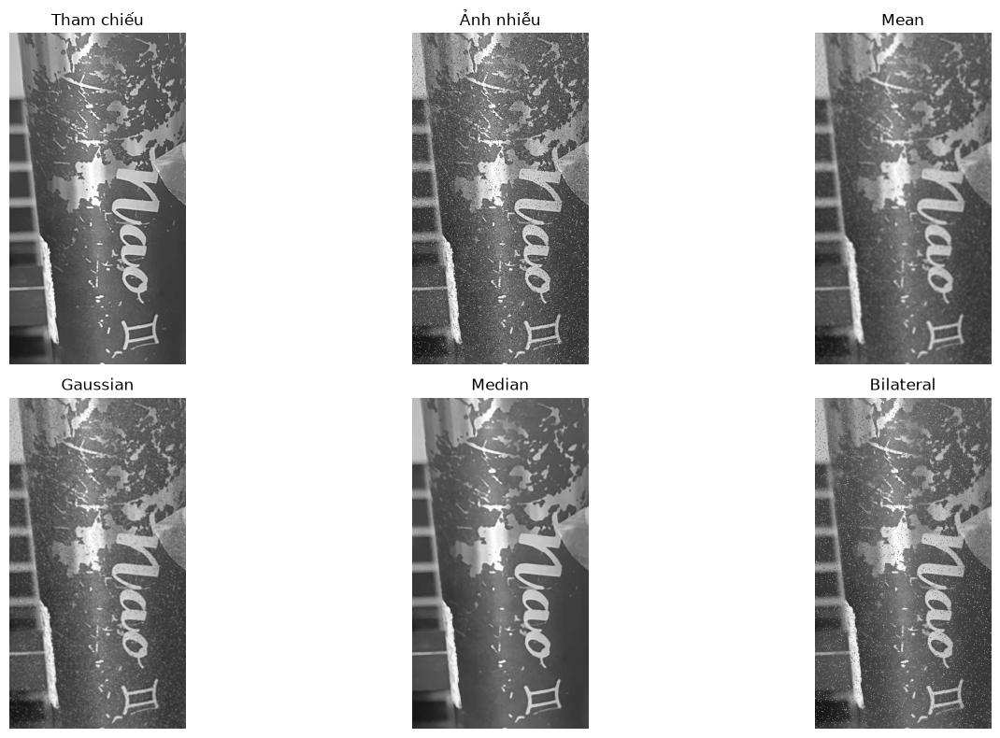

In [31]:
# Hiển thị kết quả toàn ảnh và crop vùng chi tiết
def show_grid(images, titles, save_path, columns=3):
    count = len(images)
    row_count = (count + columns - 1) // columns

    fig, axes = plt.subplots(
        row_count,
        columns,
        figsize=(5 * columns, 4 * row_count),
        squeeze=False,
    )

    for ax, image, title in zip(axes.flat, images, titles):
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")

    for ax in axes.flat[count:]:
        ax.axis("off")

    plt.tight_layout()

    save_path = Path(save_path)
    save_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(save_path, dpi=180, bbox_inches="tight")

    plt.show()
    plt.close(fig)


for noise_name, results in results_by_noise.items():
    images = [gray, noisy_images[noise_name], *results.values()]
    titles = ["Tham chiếu", "Ảnh nhiễu", *results.keys()]

    show_grid(
        images,
        titles,
        ROOT / "outputs" / "figures" / f"{noise_name}_comparison.png",
    )

    show_grid(
        [crop_detail(image) for image in images],
        titles,
        ROOT / "outputs" / "figures" / f"{noise_name}_crop.png",
    )

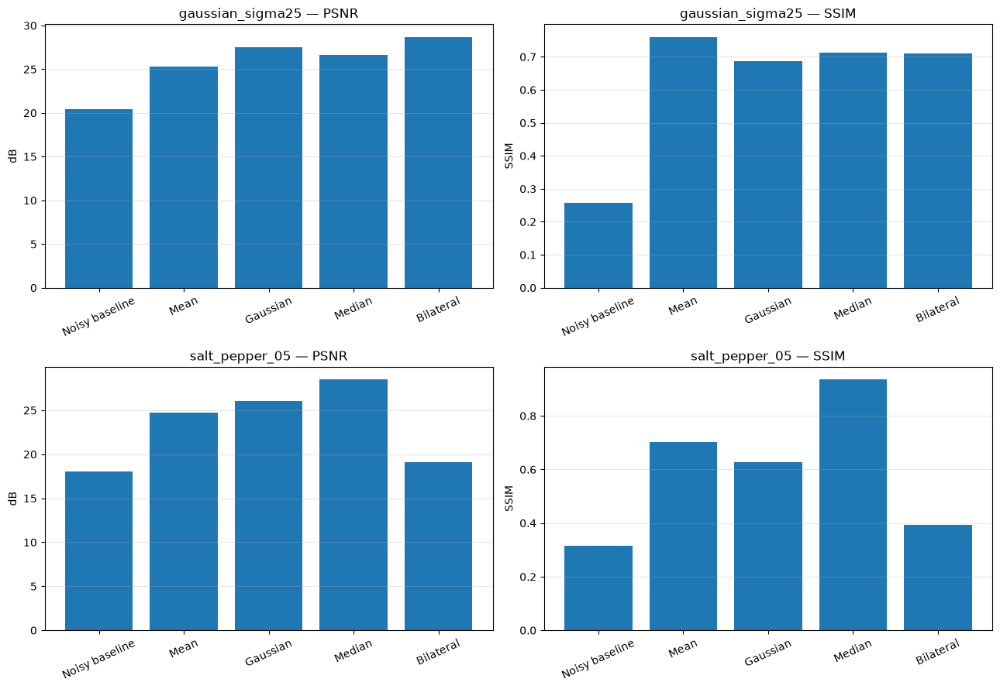

In [32]:
# Vẽ biểu đồ PSNR và SSIM
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for row_index, noise_name in enumerate(noisy_images):
    subset = metrics_df[
        metrics_df["noise"] == noise_name
    ]

    for column_index, metric in enumerate(["PSNR", "SSIM"]):
        ax = axes[row_index, column_index]

        ax.bar(subset["method"], subset[metric])
        ax.set_title(f"{noise_name} — {metric}")
        ax.set_ylabel("dB" if metric == "PSNR" else "SSIM")
        ax.tick_params(axis="x", labelrotation=25)
        ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
fig.savefig(
    ROOT / "outputs" / "figures" / "denoising_metrics.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

In [33]:
# Chạy thí nghiệm trên nhiều ảnh
all_rows = []

for image_name in ["desk", "document", "texture"]:
    reference_bgr = read_image(
        ROOT / "data" / "original" / f"{image_name}.jpg"
    )

    reference = cv2.cvtColor(
        reference_bgr,
        cv2.COLOR_BGR2GRAY,
    )

    noise_cases = {
        "gaussian_sigma25": gaussian_noise(
            reference, sigma=25, seed=SEED
        ),
        "salt_pepper_05": salt_pepper_noise(
            reference, amount=0.05, seed=SEED
        ),
    }

    for noise_name, noisy in noise_cases.items():
        all_rows.append({
            "image": image_name,
            "noise": noise_name,
            "method": "Noisy baseline",
            "params": "-",
            **evaluate(reference, noisy),
        })

        for method_name, specification in filter_methods.items():
            filtered = specification["run"](noisy)

            all_rows.append({
                "image": image_name,
                "noise": noise_name,
                "method": method_name,
                "params": specification["params"],
                **evaluate(reference, filtered),
            })

all_metrics_df = pd.DataFrame(all_rows)

all_metrics_df.to_csv(
    metrics_dir / "all_images_denoising.csv",
    index=False,
    encoding="utf-8-sig",
)

display(all_metrics_df.round(3))

,image,noise,method,params,MSE,PSNR,SSIM
0,desk,gaussian_sigma25,Noisy baseline,-,592.843,20.401,0.257
1,desk,gaussian_sigma25,Mean,k=5,190.399,25.334,0.761
2,desk,gaussian_sigma25,Gaussian,"k=5, sigma=1.0",116.010,27.486,0.688
3,desk,gaussian_sigma25,Median,k=5,141.384,26.627,0.713
4,desk,gaussian_sigma25,Bilateral,"d=9, sigma_color=50, sigma_space=50",87.648,28.703,0.711
5,desk,salt_pepper_05,Noisy baseline,-,1014.948,18.066,0.314
6,desk,salt_pepper_05,Mean,k=5,218.425,24.738,0.702
7,desk,salt_pepper_05,Gaussian,"k=5, sigma=1.0",161.313,26.054,0.627
8,desk,salt_pepper_05,Median,k=5,91.660,28.509,0.936
9,desk,salt_pepper_05,Bilateral,"d=9, sigma_color=50, sigma_space=50",805.997,19.067,0.394


## Nhận xét tổng kết

### Toán tử điểm ảnh và lọc không gian

Các phép cộng và nhân cường độ cho phép điều chỉnh mức sáng
và chênh lệch cường độ của ảnh, nhưng có thể làm mất chi tiết
khi kết quả bị clipping. Phép âm bản đảo sáng–tối, còn phân ngưỡng
chuyển ảnh thành hai mức nhưng chưa tách được hoàn chỉnh các
đối tượng trong cảnh phức tạp.

Với lọc trung bình, tăng kích thước kernel làm ảnh mịn hơn
nhưng mất nhiều chi tiết nhỏ hơn. Với Gaussian có kernel cố định,
tăng sigma cũng làm mức làm mờ tăng. Sharpening làm nổi đường biên
và họa tiết nhưng đồng thời có thể làm rõ các chi tiết hạt.

Sobel và Prewitt tạo bản đồ gradient theo hai hướng và độ lớn
gradient kết hợp. Kernel tùy chỉnh và hình kiểm chứng cho thấy
hướng của các hệ số quyết định hướng làm mịn.

### Khử nhiễu Gaussian

Với các cấu hình đã khảo sát, phương pháp đạt PSNR cao nhất
thay đổi theo ảnh:

| Ảnh | Phương pháp | PSNR cao nhất |
|---|---|---:|
| desk | Bilateral | 28.703 dB |
| document | Gaussian | 28.707 dB |
| texture | Bilateral | 29.172 dB |

Trên ảnh texture, chênh lệch PSNR giữa bilateral và Gaussian
chỉ khoảng 0.031 dB, nên chưa đủ để khẳng định một ưu thế rõ rệt.

Mean đạt SSIM cao nhất trên cả ba ảnh: lần lượt là 0.761,
0.767 và 0.755. Kết quả cho thấy việc xếp hạng bộ lọc phụ thuộc
vào tiêu chí đánh giá; PSNR cao nhất không đồng nghĩa SSIM cao nhất.

### Khử nhiễu muối tiêu

Median đạt MSE thấp nhất, PSNR và SSIM cao nhất trên cả ba ảnh
trong các cấu hình khảo sát:

| Ảnh | MSE | PSNR | SSIM |
|---|---:|---:|---:|
| desk | 91.660 | 28.509 dB | 0.936 |
| document | 74.838 | 29.390 dB | 0.948 |
| texture | 43.956 | 31.701 dB | 0.890 |

Kết quả phù hợp với nguyên lý chọn trung vị: các pixel nhiễu
cực đoan có thể bị loại khi không chiếm phần lớn cửa sổ lân cận.

Bilateral cải thiện ít hơn với loại nhiễu này. Một nguyên nhân
có thể là chênh lệch cường độ lớn giữa pixel nhiễu và lân cận
làm giảm khả năng kết hợp chúng trong phép trung bình có trọng số.

### Giới hạn và hướng mở rộng

Thí nghiệm sử dụng ba ảnh, một mức nhiễu Gaussian, một tỷ lệ
muối tiêu và một seed. Các tham số chưa được tối ưu riêng
cho từng phương pháp.

Khảo sát kích thước kernel hiện được thực hiện trên ảnh gốc;
chưa đủ cơ sở kết luận kích thước nào khử nhiễu tối ưu.

Các chỉ số được tính so với ảnh trước khi thêm nhiễu, không phải
ảnh sạch tuyệt đối. Thời gian xử lý phụ thuộc vào kích thước ảnh,
cấu hình máy và trạng thái hệ thống.

Có thể mở rộng bằng nhiều mức nhiễu, nhiều seed, khảo sát kernel
trên ảnh nhiễu và bổ sung hình crop trên ảnh tài liệu, ảnh kết cấu.
Việc lựa chọn bộ lọc cần xét đồng thời loại nhiễu, đặc điểm ảnh,
chỉ số đánh giá và yêu cầu bảo toàn chi tiết.